In [109]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import time
import anndata as an
import scanpy as sc
import scanpy.external as sce
import h5py
import scipy
from scipy.stats import pearsonr
from scipy.spatial.distance import cdist
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm
import re
import matplotlib.colors as mcolors
import networkx as nx
import itertools

from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from collections import defaultdict
from sklearn.metrics import pairwise_distances
from scipy.spatial.distance import euclidean
import matplotlib.lines as mlines

sc.settings.verbosity = 1

# Load in processed data

In [110]:
%%time
path = "/nfs/turbo/umms-indikar/shared/projects/hybrid_reprogramming/anndata/processed_all_groups.h5ad"
adata = sc.read_h5ad(path)
sc.logging.print_memory_usage()
adata

Memory usage: current 7.43 GB, difference +5.06 GB
CPU times: user 314 ms, sys: 1.48 s, total: 1.79 s
Wall time: 5.34 s


/nfs/turbo/umms-indikar/Cooper/conda_envs/rapids/lib/python3.13/site-packages/anndata/logging.py:57: FutureWarning: The specified parameters ('newline',) are no longer positional. Please specify them like `newline=False`
  print(format_memory_usage(get_memory_usage(), msg, newline))


AnnData object with n_obs × n_vars = 15950 × 25042
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes', 'pooled_condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier', 'S_score', 'G2M_score', 'phase', 'leiden', 'cluster_str', 'leiden_split'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'filter_pass', 'highly_variable', 'highly_variable_rank', 'm

# Compute distances, kNN neighbors, and UMAP

In [127]:
condition_key = 'pooled_condition'
n_per_cond = 500
random_seed = 42
metrics = ['euclidean', 'cosine', 'manhattan', 'correlation']
n_pcs = 50
n_neighbors = 15
conds = ['Control', 'siPRRX1', 'mmMYOD1', 'siPRRX1/mmMYOD1']

rng = np.random.RandomState(random_seed)


# ---- 1) Sample cells per condition ----
sample_idx = []
for c in conds:
    idx_c = np.where(adata.obs[condition_key] == c)[0]
    k = min(n_per_cond, len(idx_c))
    chosen = rng.choice(idx_c, size=k, replace=False)
    sample_idx.extend(chosen.tolist())

# Order cells by condition
sample_idx = np.array(sample_idx)
ordered = []
for c in conds:
    mask = (adata.obs[condition_key].values[sample_idx] == c)
    ordered.extend(sample_idx[mask].tolist())
ordered = np.array(ordered)

adata_sub = adata[ordered].copy()

# ---- 2) Get representation ----
use_rep = 'X_pca'
X = adata_sub.obsm[use_rep]

print(f"Subset adata for {n_per_cond} cells per condition and ordered cells.")
print("Computing neighbors and UMAP...\n")

# ---- 3) Compute kNN neighbors and UMAP embeddings ----
umap_embeddings = {}

for metric in metrics:
    sc.pp.neighbors(
        adata_sub,
        n_neighbors=n_neighbors,
        use_rep=use_rep,
        metric=metric
    )
    sc.tl.umap(adata_sub, random_state=random_seed)
    umap_embeddings[metric] = adata_sub.obsm['X_umap'].copy()

print("Done. Computing full pairwise distance matrices...")
# ---- 4) Compute full pairwise distance matrices ----
distance_matrices = {}
for metric in metrics:
    print(f"\t{metric}...")
    D = pairwise_distances(X, metric=metric)
    distance_matrices[metric] = D
    
print("\nFinished.")

Subset adata for 500 cells per condition and ordered cells.
Computing neighbors and UMAP...

Done. Computing full pairwise distance matrices...
	euclidean...
	cosine...
	manhattan...
	correlation...

Finished.


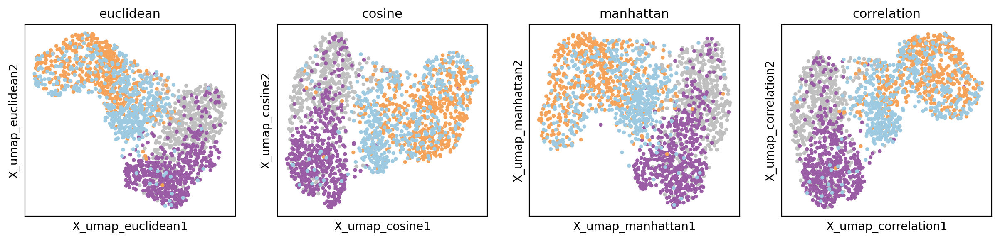

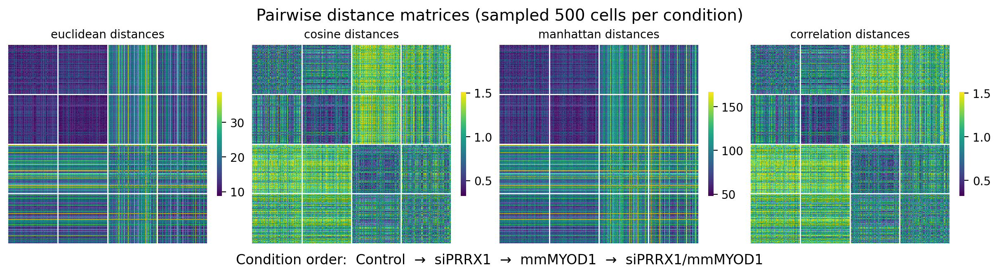

In [145]:
# ---- 5) Plot UMAPs ----
fig_umap, axes_umap = plt.subplots(1, 4, figsize=(15, 3), dpi=200)#, constrained_layout=True)
# fig_umap, axes_umap = plt.subplots(4, 1, figsize=(4, 12), constrained_layout=True)
axes_umap = axes_umap.flatten()

for ax, metric in zip(axes_umap, metrics):
    key = f"X_umap_{metric}"
    adata_sub.obsm[key] = umap_embeddings[metric]

    sc.pl.embedding(
        adata_sub,
        basis=key,
        color=condition_key,
        size=45,
        ax=ax,
        legend_loc='none',
        # legend_fontsize='xx-small',
        show=False
    )
    ax.set_title(f"{metric}", fontsize=11)

# fig_umap.suptitle("UMAP embeddings by distance metric", fontsize=14)
plt.show()


# ---- 6) Plot heatmaps of true distance matrices ----
# fig_heat, axes_heat = plt.subplots(1, len(metrics), figsize=(4*len(metrics), 4), constrained_layout=True)
fig_heat, axes_heat = plt.subplots(1, len(metrics), figsize=(12, 3), constrained_layout=True)
axes_heat = axes_heat.flatten()

cond_order = adata_sub.obs[condition_key].values
boundaries = []
current_cond = cond_order[0]
for i, cond in enumerate(cond_order):
    if cond != current_cond:
        boundaries.append(i)
        current_cond = cond

for ax, metric in zip(axes_heat, metrics):
    D = distance_matrices[metric]
    nonzero = D[D > 0]
    vmin, vmax = np.percentile(nonzero, [1, 99])

    sns.heatmap(
        D,
        ax=ax,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        square=True,
        xticklabels=False,
        yticklabels=False,
        cbar=True,
        cbar_kws={'shrink': 0.5},
    )
    ax.set_title(f"{metric} distances", fontsize=10)

    for b in boundaries:
        ax.axhline(b, color="white", linewidth=1)
        ax.axvline(b, color="white", linewidth=1)
        
condition_order_str = "  →  ".join(conds)
fig_heat.text(
    0.5, -0.05,  # centered below the figure
    f"Condition order:  {condition_order_str}",
    ha="center",
    fontsize=12
)

fig_heat.suptitle(f"Pairwise distance matrices (sampled {n_per_cond} cells per condition)", fontsize=14)
plt.show()

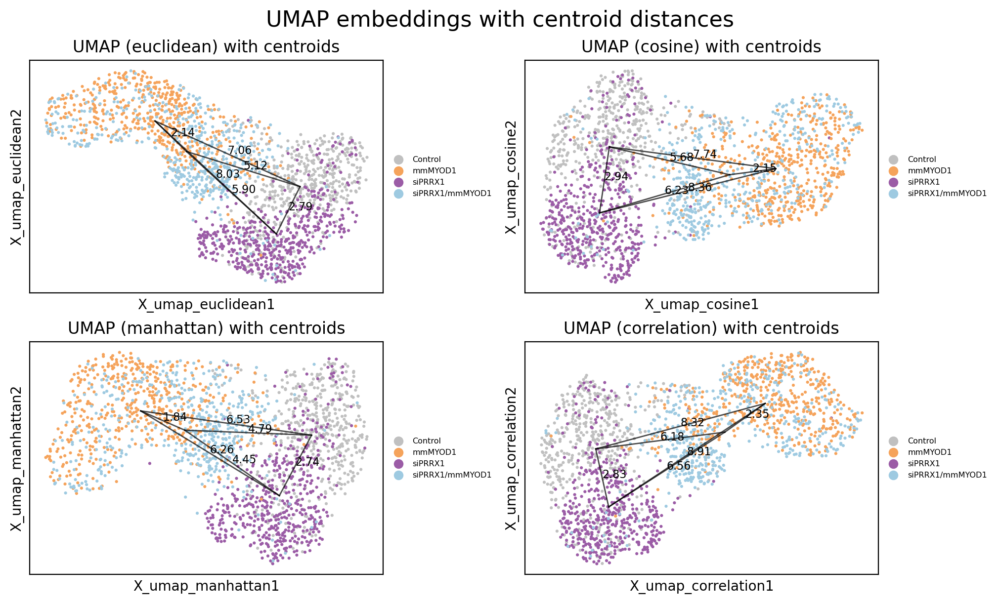

In [113]:
fig_umap, axes_umap = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
axes_umap = axes_umap.flatten()

for ax, metric in zip(axes_umap, metrics):
    key = f"X_umap_{metric}"
    coords = adata_sub.obsm[key]

    # Compute centroids
    centroids = {}
    for cond in conds:
        centroids[cond] = coords[adata_sub.obs[condition_key] == cond].mean(axis=0)

    # Plot UMAP points
    sc.pl.embedding(
        adata_sub,
        basis=key,
        color=condition_key,
        size=20,
        ax=ax,
        legend_fontsize='xx-small',
        show=False
    )

    # Overlay lines between centroids and annotate distances
    for i, cond1 in enumerate(conds):
        for j, cond2 in enumerate(conds):
            if i < j:
                c1 = centroids[cond1]
                c2 = centroids[cond2]
                dist = euclidean(c1, c2)
                
                # Draw line connecting centroids
                line = mlines.Line2D(
                    [c1[0], c2[0]],
                    [c1[1], c2[1]],
                    color='black',
                    linewidth=1,
                    alpha=0.7
                )
                ax.add_line(line)

                # Annotate with distance
                mid_x, mid_y = (c1[0]+c2[0])/2, (c1[1]+c2[1])/2
                ax.text(
                    mid_x, mid_y,
                    f"{dist:.2f}",
                    fontsize=8,
                    color='black'
                )

    ax.set_title(f"UMAP ({metric}) with centroids", fontsize=12)

fig_umap.suptitle("UMAP embeddings with centroid distances", fontsize=16)
plt.show()

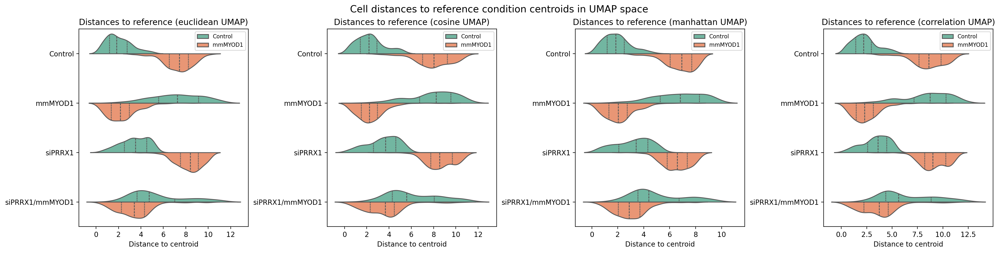

In [114]:
reference_conditions = ['Control', 'mmMYOD1']  # can adjust
metrics = ['euclidean', 'cosine', 'manhattan', 'correlation']

violin_dfs = []
for metric in metrics:
    key = f"X_umap_{metric}"
    coords = adata_sub.obsm[key]

    # Compute centroids
    centroids = {cond: coords[adata_sub.obs[condition_key]==cond].mean(axis=0) for cond in conds}

    # Compute distances to each reference
    for ref in reference_conditions:
        ref_centroid = centroids[ref]

        # Distance from every cell to ref centroid
        dists = np.linalg.norm(coords - ref_centroid, axis=1)

        df = pd.DataFrame({
            'condition': adata_sub.obs[condition_key].values,
            'distance_to': dists,
            'reference': ref,
            'metric': metric
        })
        violin_dfs.append(df)

violin_df = pd.concat(violin_dfs, ignore_index=True)

fig, axes = plt.subplots(1, len(metrics), figsize=(5*len(metrics), 5), constrained_layout=True)
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    df_plot = violin_df[violin_df['metric'] == metric]
    
    sns.violinplot(
        x='distance_to',
        y='condition',
        hue='reference',
        data=df_plot,
        split=True,
        inner="quartile",
        palette="Set2",
        ax=ax
    )
    
    ax.set_title(f"Distances to reference ({metric} UMAP)")
    ax.set_xlabel("Distance to centroid")
    ax.set_ylabel("")
    ax.legend(title="", fontsize=8, title_fontsize=9)

plt.suptitle("Cell distances to reference condition centroids in UMAP space", fontsize=14)
plt.show()

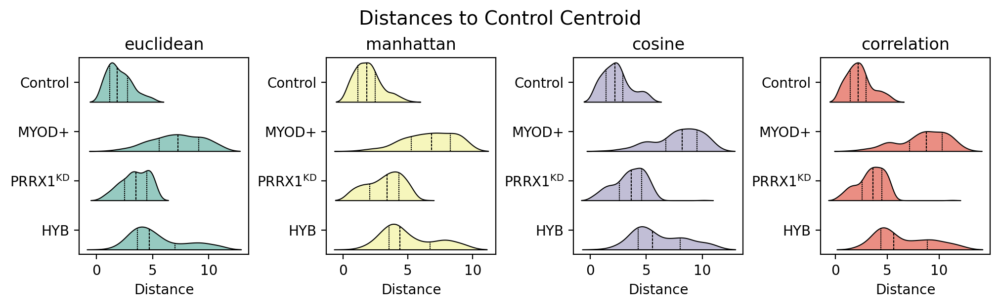

In [150]:
reference_condition = 'Control'
metrics = ['euclidean', 'manhattan', 'cosine', 'correlation']

# ---- Prepare dataframe ----
violin_dfs = []

for metric in metrics:
    key = f"X_umap_{metric}"
    coords = adata_sub.obsm[key]

    centroids = {cond: coords[adata_sub.obs[condition_key] == cond].mean(axis=0) for cond in conds}
    ref_centroid = centroids[reference_condition]

    # Distance from every cell to reference centroid
    dists = np.linalg.norm(coords - ref_centroid, axis=1)

    df = pd.DataFrame({
        'condition': adata_sub.obs[condition_key].values,
        'distance_to_Control': dists,
        'metric': metric,
        'side': 'left'  # dummy hue to force half violin
    })
    violin_dfs.append(df)

violin_df = pd.concat(violin_dfs, ignore_index=True)

cond_map = {
    'Control': 'Control',
    'mmMYOD1': 'MYOD+',
    'siPRRX1': r'PRRX1$^{\mathrm{KD}}$',
    'siPRRX1/mmMYOD1': 'HYB',
}
violin_df["condition_label"] = violin_df["condition"].map(cond_map)

# ---- Plot half violins ----
# sns.set(style="whitegrid")

palette = sns.color_palette("Set3", n_colors=len(metrics))
metric_colors = dict(zip(metrics, palette))


fig, axes = plt.subplots(1, len(metrics), figsize=(10, 3), constrained_layout=True, dpi=200)
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    df_plot = violin_df[violin_df['metric'] == metric]

    sns.violinplot(
        x='distance_to_Control',
        y='condition_label',
        hue='side',           # dummy hue
        data=df_plot,
        split=True,          # makes half violin
        inner="quartile",
        palette={"left": metric_colors[metric]},#"#66c2a5"},
        ax=ax,
        linewidth=0.75,
        linecolor='k',
    )
        
    ax.set_title(f"{metric}")
    ax.set_xlabel("Distance")
    ax.set_ylabel("")
    ax.legend_.remove()

plt.suptitle("Distances to Control Centroid", fontsize=14)
plt.show()

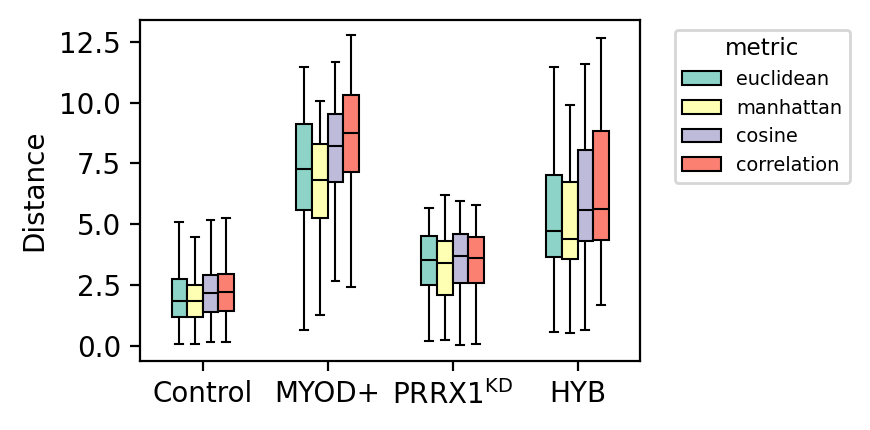

In [159]:
plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = 4.5, 2.25

metric_order = ['euclidean', 'manhattan', 'cosine', 'correlation']

sns.boxplot(
    data=violin_df,
    x='condition_label',
    y='distance_to_Control',
    hue='metric',
    linecolor='k',
    linewidth=0.75,
    showfliers=False,
    width=0.5,
    hue_order=metric_order,
    palette='Set3',
    saturation=1,
)

plt.xlabel("")
plt.ylabel('Distance')

# plt.title('Distances to Control Centroid')

plt.legend(
    title='metric',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    title_fontsize='small',
    fontsize='x-small',
)

plt.tight_layout()
plt.show()

In [84]:
summary = violin_df.groupby(["metric", "condition"], observed=True)["distance_to_Control"].agg(["mean", "median", "std", "count"]).reset_index()
summary

,metric,condition,mean,median,std,count
0,correlation,Control,2.306498,2.195757,1.244998,500
1,correlation,mmMYOD1,8.443122,8.736883,2.359651,500
2,correlation,siPRRX1,3.418388,3.598654,1.349113,500
3,correlation,siPRRX1/mmMYOD1,6.522997,5.626533,2.673080,500
4,cosine,Control,2.323232,2.185287,1.265584,500
5,cosine,mmMYOD1,7.898102,8.220078,2.138113,500
6,cosine,siPRRX1,3.506620,3.683191,1.428956,500
7,cosine,siPRRX1/mmMYOD1,6.151744,5.573928,2.372479,500
8,euclidean,Control,2.038468,1.828332,1.126855,500
9,euclidean,mmMYOD1,7.177557,7.249888,2.269635,500


In [117]:
adata.obs['leiden_split'].value_counts(sort=False)

leiden_split
C1    6078
C2     824
C3      58
H1    2060
H3     622
H2     769
M1     706
M2     729
M3     674
P2    1508
P1    1166
P3     756
Name: count, dtype: int64

# By cluster

In [160]:
%%time
condition_key = 'leiden_split'
n_per_cond = 500
random_seed = 42
metrics = ['euclidean', 'cosine', 'manhattan', 'correlation']
n_pcs = 50
n_neighbors = 15
conds = ['C1', 'C2', 'P1', 'P2', 'P3', 'M1', 'M2', 'M3', 'H1', 'H2', 'H3']

rng = np.random.RandomState(random_seed)


# ---- 1) Sample cells per condition ----
sample_idx = []
for c in conds:
    idx_c = np.where(adata.obs[condition_key] == c)[0]
    k = min(n_per_cond, len(idx_c))
    chosen = rng.choice(idx_c, size=k, replace=False)
    sample_idx.extend(chosen.tolist())

# Order cells by condition
sample_idx = np.array(sample_idx)
ordered = []
for c in conds:
    mask = (adata.obs[condition_key].values[sample_idx] == c)
    ordered.extend(sample_idx[mask].tolist())
ordered = np.array(ordered)

adata_sub = adata[ordered].copy()

# ---- 2) Get representation ----
use_rep = 'X_pca'
X = adata_sub.obsm[use_rep]

print(f"Subset adata for {n_per_cond} cells per condition and ordered cells.")
print("Computing neighbors and UMAP...\n")

# ---- 3) Compute kNN neighbors and UMAP embeddings ----
umap_embeddings = {}

for metric in metrics:
    sc.pp.neighbors(
        adata_sub,
        n_neighbors=n_neighbors,
        use_rep=use_rep,
        metric=metric
    )
    sc.tl.umap(adata_sub, random_state=random_seed)
    umap_embeddings[metric] = adata_sub.obsm['X_umap'].copy()

print("Done. Computing full pairwise distance matrices...")
# ---- 4) Compute full pairwise distance matrices ----
distance_matrices = {}
for metric in metrics:
    print(f"\t{metric}...")
    D = pairwise_distances(X, metric=metric)
    distance_matrices[metric] = D
    
print("\nFinished.")

Subset adata for 500 cells per condition and ordered cells.
Computing neighbors and UMAP...

Done. Computing full pairwise distance matrices...
	euclidean...
	cosine...
	manhattan...
	correlation...

Finished.
CPU times: user 48.6 s, sys: 1.31 s, total: 49.9 s
Wall time: 50.6 s


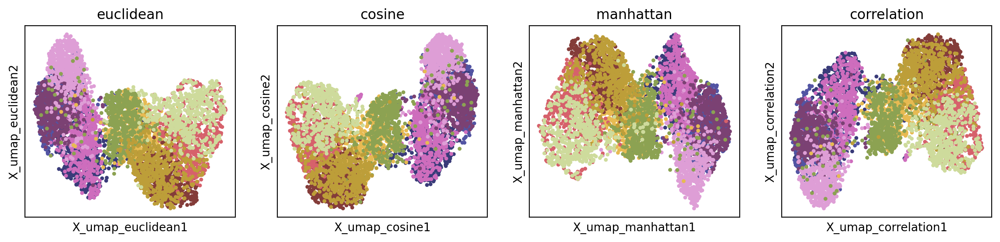

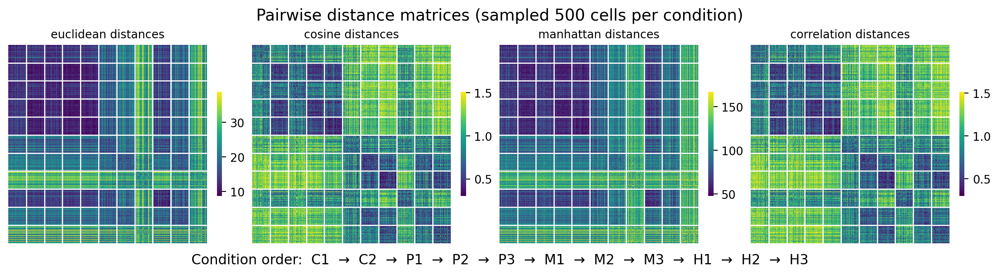

In [161]:
# ---- 5) Plot UMAPs ----
# fig_umap, axes_umap = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
fig_umap, axes_umap = plt.subplots(1, 4, figsize=(15, 3), dpi=200)
axes_umap = axes_umap.flatten()

for ax, metric in zip(axes_umap, metrics):
    key = f"X_umap_{metric}"
    adata_sub.obsm[key] = umap_embeddings[metric]

    sc.pl.embedding(
        adata_sub,
        basis=key,
        color=condition_key,
        size=45,
        ax=ax,
        legend_loc='none',
        # legend_fontsize='xx-small',
        show=False
    )
    ax.set_title(f"{metric}", fontsize=12)

# fig_umap.suptitle("UMAP embeddings by distance metric", fontsize=14)
plt.show()


# ---- 6) Plot heatmaps of true distance matrices ----
# fig_heat, axes_heat = plt.subplots(1, len(metrics), figsize=(4*len(metrics), 4), constrained_layout=True)
fig_heat, axes_heat = plt.subplots(1, len(metrics), figsize=(12, 3), constrained_layout=True)
axes_heat = axes_heat.flatten()

cond_order = adata_sub.obs[condition_key].values
boundaries = []
current_cond = cond_order[0]
for i, cond in enumerate(cond_order):
    if cond != current_cond:
        boundaries.append(i)
        current_cond = cond

for ax, metric in zip(axes_heat, metrics):
    D = distance_matrices[metric]
    nonzero = D[D > 0]
    vmin, vmax = np.percentile(nonzero, [1, 99])

    sns.heatmap(
        D,
        ax=ax,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        square=True,
        xticklabels=False,
        yticklabels=False,
        cbar=True,
        cbar_kws={'shrink': 0.5},
    )
    ax.set_title(f"{metric} distances", fontsize=10)

    for b in boundaries:
        ax.axhline(b, color="white", linewidth=1)
        ax.axvline(b, color="white", linewidth=1)
        
condition_order_str = "  →  ".join(conds)
fig_heat.text(
    0.5, -0.05,  # centered below the figure
    f"Condition order:  {condition_order_str}",
    ha="center",
    fontsize=12
)

fig_heat.suptitle(f"Pairwise distance matrices (sampled {n_per_cond} cells per condition)", fontsize=14)
plt.show()

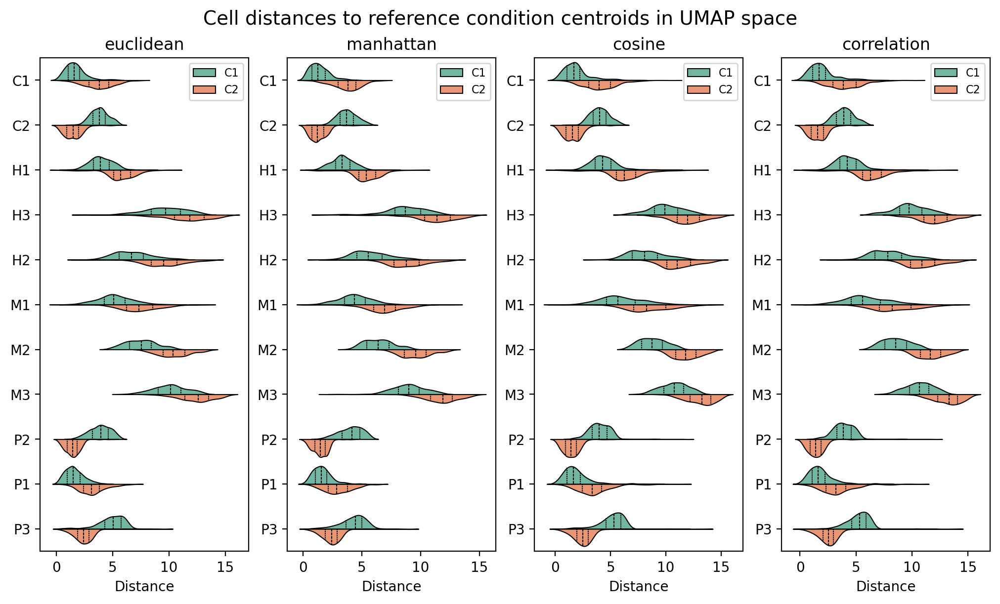

In [164]:
reference_conditions = ['C1', 'C2']  # can adjust
metrics = ['euclidean', 'manhattan', 'cosine', 'correlation']

violin_dfs = []
for metric in metrics:
    key = f"X_umap_{metric}"
    coords = adata_sub.obsm[key]

    # Compute centroids
    centroids = {cond: coords[adata_sub.obs[condition_key]==cond].mean(axis=0) for cond in conds}

    # Compute distances to each reference
    for ref in reference_conditions:
        ref_centroid = centroids[ref]

        # Distance from every cell to ref centroid
        dists = np.linalg.norm(coords - ref_centroid, axis=1)

        df = pd.DataFrame({
            'condition': adata_sub.obs[condition_key].values,
            'distance_to': dists,
            'reference': ref,
            'metric': metric
        })
        violin_dfs.append(df)

violin_df = pd.concat(violin_dfs, ignore_index=True)

fig, axes = plt.subplots(1, len(metrics), figsize=(10, 6), constrained_layout=True, dpi=200)
# fig, axes = plt.subplots(1, len(metrics), figsize=(16, 10), constrained_layout=True)
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    df_plot = violin_df[violin_df['metric'] == metric]
    
    sns.violinplot(
        x='distance_to',
        y='condition',
        hue='reference',
        data=df_plot,
        split=True,
        inner="quartile",
        palette="Set2",
        ax=ax,
        linewidth=0.75,
        linecolor='k',
    )
    
    ax.set_title(f"{metric}")
    ax.set_xlabel("Distance")
    ax.set_ylabel("")
    ax.legend(title="", fontsize=8, title_fontsize=9)

plt.suptitle("Cell distances to reference condition centroids in UMAP space", fontsize=14)
plt.show()

In [122]:
violin_df.head()

,condition,distance_to,reference,metric
0,C1,1.558308,C1,euclidean
1,C1,2.353323,C1,euclidean
2,C1,5.368773,C1,euclidean
3,C1,1.065905,C1,euclidean
4,C1,0.367590,C1,euclidean


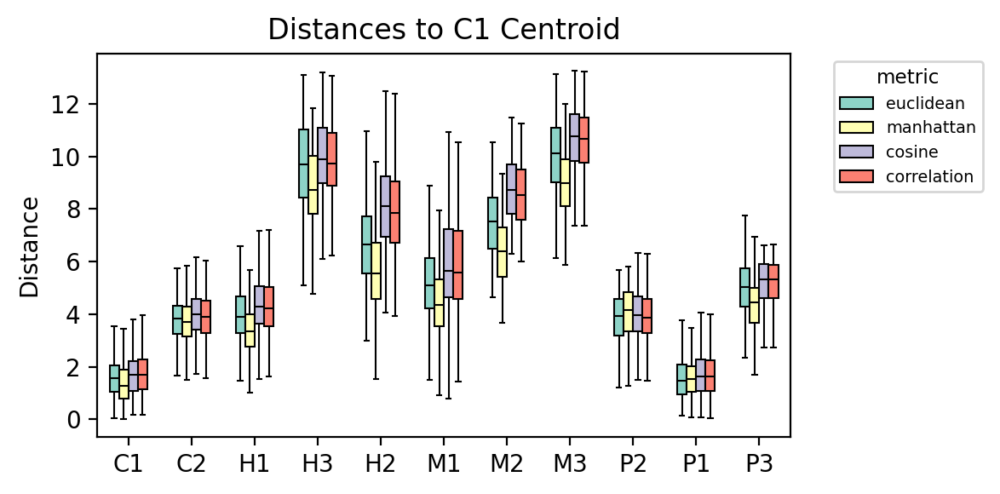

In [175]:
plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = 6, 3

metric_order = ['euclidean', 'manhattan', 'cosine', 'correlation']

df_c1 = violin_df[violin_df['reference'] == 'C1']

sns.boxplot(
    data=df_c1,
    x='condition',
    y='distance_to',
    hue='metric',
    linecolor='k',
    linewidth=0.75,
    showfliers=False,
    width=0.6,
    hue_order=metric_order,
    palette='Set3',
    saturation=1,
)

plt.xlabel("")
plt.ylabel('Distance')

plt.title('Distances to C1 Centroid')

plt.legend(
    title='metric',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize='x-small',
    title_fontsize='small',
)

plt.tight_layout()
plt.show()

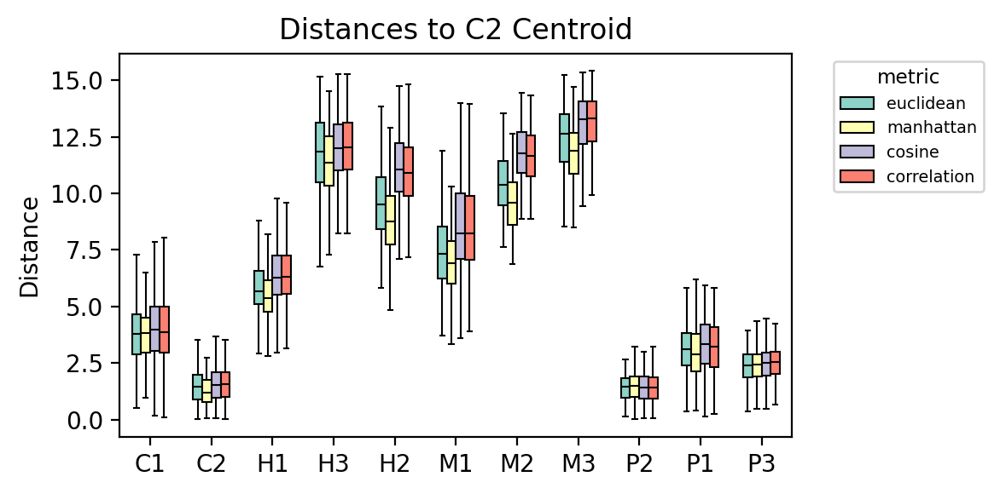

In [177]:
plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = 6, 3

metric_order = ['euclidean', 'manhattan', 'cosine', 'correlation']

df_c2 = violin_df[violin_df['reference'] == 'C2']

sns.boxplot(
    data=df_c2,
    x='condition',
    y='distance_to',
    hue='metric',
    linecolor='k',
    linewidth=0.75,
    showfliers=False,
    width=0.6,
    hue_order=metric_order,
    palette='Set3',
    saturation=1,
)

plt.xlabel("")
plt.ylabel('Distance')

plt.title('Distances to C2 Centroid')

plt.legend(
    title='metric',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize='x-small',
    title_fontsize='small',
)

plt.tight_layout()
plt.show()

#

# kNN distance matrices

In [50]:
condition_key = 'pooled_condition'
n_per_cond = 500
random_seed = 42
metrics = ['euclidean', 'cosine', 'manhattan', 'correlation']
n_pcs = 50
n_neighbors=15

rng = np.random.RandomState(random_seed)

# 1) sample up to n_per_cond per condition
conds = ['Control', 'siPRRX1', 'mmMYOD1', 'siPRRX1/mmMYOD1']

sample_idx = []
for c in conds:
    idx_c = np.where(adata.obs[condition_key] == c)[0]
    k = min(n_per_cond, len(idx_c))
    chosen = rng.choice(idx_c, size=k, replace=False)
    sample_idx.extend(chosen.tolist())
    
# keep original ordering by condition
sample_idx = np.array(sample_idx)
ordered = []
for c in conds:
    mask = (adata.obs[condition_key].values[sample_idx] == c)
    ordered.extend(sample_idx[mask].tolist())
ordered = np.array(ordered)


# 2) subset adata (make a copy)
adata_sub = adata[ordered].copy()

use_rep = 'X_pca'
X = adata_sub.obsm[use_rep]

# 4) compute neighbors for each metric and save dense distance matrices
distance_matrices = {}
for metric in metrics:
    sc.pp.neighbors(adata_sub, n_neighbors=n_neighbors, use_rep=use_rep, metric=metric)
    dmat = adata_sub.obsp['distances'].toarray()
    distance_matrices[metric] = dmat

print("Finished.")

computing neighbors
    finished (0:00:00)
computing neighbors
    finished (0:00:00)
computing neighbors
    finished (0:00:00)
computing neighbors
    finished (0:00:00)
Finished.


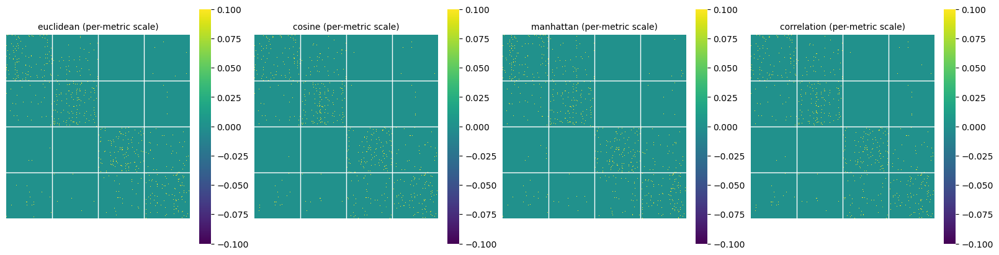

In [51]:
both_scales = False

### Add grid lines to separate conditions
cond_order = adata_sub.obs[condition_key].values
boundaries = []
current_cond = cond_order[0]

for i, cond in enumerate(cond_order):
    if cond != current_cond:
        boundaries.append(i)
        current_cond = cond

        
if both_scales:
    n = len(metrics)
    fig, axes = plt.subplots(2, n, figsize=(4*n, 8), constrained_layout=True)
    axes = axes.flatten()  # flatten for easy indexing

    # Compute global vmin/vmax across all metrics
    all_vals = np.concatenate([D.ravel() for D in distance_matrices.values()])
    global_vmin, global_vmax = np.percentile(all_vals, [1, 99])

    # ---- Top row: per-metric scaling ----
    for i, metric in enumerate(metrics):
        D = distance_matrices[metric]
        vmin, vmax = np.percentile(D, [1, 99])
        sns.heatmap(
            D,
            ax=axes[i],
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            square=True,
            xticklabels=False,
            yticklabels=False,
            cbar=True,
        )
        axes[i].set_title(f"{metric} (per-metric scale)", fontsize=10)

    # ---- Bottom row: global scaling ----
    for i, metric in enumerate(metrics):
        D = distance_matrices[metric]
        sns.heatmap(
            D,
            ax=axes[n + i],
            cmap="viridis",
            vmin=global_vmin,
            vmax=global_vmax,
            square=True,
            xticklabels=False,
            yticklabels=False,
            cbar=True,
        )
        axes[n + i].set_title(f"{metric} (global scale)", fontsize=10)

    fig.suptitle(
        f"Distance matrices — {len(ordered)} cells (sampled ≤{n_per_cond}/condition)",
        fontsize=14
    )
    plt.show()
        
else:
    n = len(metrics)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4), constrained_layout=True)

    for ax, metric in zip(axes, metrics):
        D = distance_matrices[metric] 
        vmin, vmax = np.percentile(D, [1, 99])
        sns.heatmap(
            D,
            ax=ax,
            cmap='viridis',
            vmin=vmin,
            vmax=vmax,
            square=True,
            xticklabels=False,
            yticklabels=False,
            cbar=True,
        )
        ax.set_title(f"{metric} (per-metric scale)", fontsize=10)
        
        for b in boundaries:
            ax.axhline(b, color="white", linewidth=1)
            ax.axvline(b, color="white", linewidth=1)

    plt.show()

## UMAPs with diff distance metrics

computing neighbors
    finished (0:00:00)
computing UMAP
    finished (0:00:00)
computing neighbors
    finished (0:00:00)
computing UMAP
    finished (0:00:00)
computing neighbors
    finished (0:00:00)
computing UMAP
    finished (0:00:00)
computing neighbors
    finished (0:00:00)
computing UMAP
    finished (0:00:00)


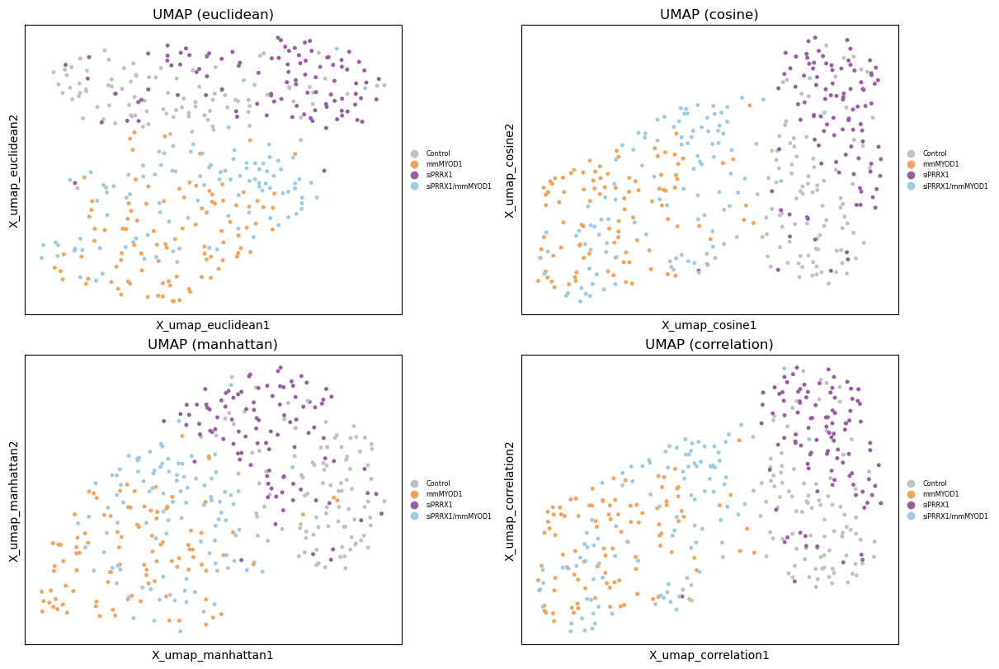

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    # recompute neighbors with given metric
    sc.pp.neighbors(
        adata_sub, 
        n_neighbors=n_neighbors, 
        use_rep=use_rep, 
        metric=metric
    )
    
    key = f"X_umap_{metric}"
    sc.tl.umap(adata_sub)
    adata_sub.obsm[key] = adata_sub.obsm["X_umap"].copy()

    sc.pl.embedding(
        adata_sub,
        basis=key,
        color=condition_key,
        size=50,
        # frameon=False,
        ax=ax,
        show=False,
        title=f"UMAP ({metric})",
        legend_fontsize='xx-small',
    )

plt.show()

# Pairwise distances

In [47]:
condition_key = 'pooled_condition'
n_per_cond = 100
random_seed = 42
metrics = ['euclidean', 'cosine', 'manhattan', 'correlation']
n_pcs = 50
# n_neighbors=15

rng = np.random.RandomState(random_seed)

# 1) sample n cells per condition
conds = ['Control', 'siPRRX1', 'mmMYOD1', 'siPRRX1/mmMYOD1']
sample_idx = []
for c in conds:
    idx_c = np.where(adata.obs[condition_key] == c)[0]
    k = min(n_per_cond, len(idx_c))  # handles small groups
    chosen = rng.choice(idx_c, size=k, replace=False)
    sample_idx.extend(chosen.tolist())

ordered_idx = []
for c in conds:
    mask = adata.obs[condition_key].values[sample_idx] == c
    ordered_idx.extend(np.array(sample_idx)[mask].tolist())

adata_sub = adata[ordered_idx].copy()


X = adata_sub.obsm["X_pca"][:, :n_pcs]


# 3) compute full pairwise distance matrices
distance_matrices = {}
for metric in metrics:
    D = pairwise_distances(X, metric=metric)
    distance_matrices[metric] = D

print("Finished.")

Finished.


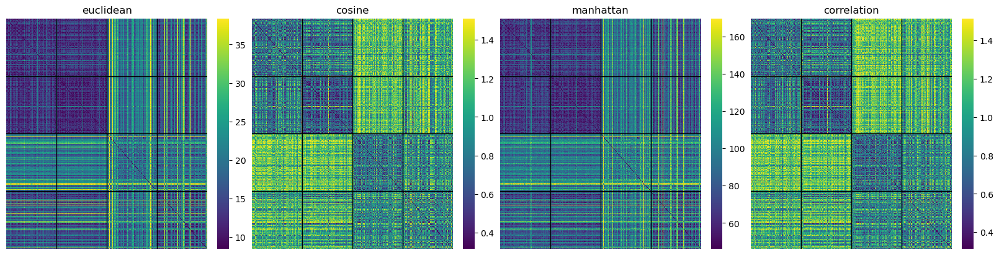

In [49]:
### Add grid lines to separate conditions
cond_order = adata_sub.obs[condition_key].values
boundaries = []
current_cond = cond_order[0]

for i, cond in enumerate(cond_order):
    if cond != current_cond:
        boundaries.append(i)
        current_cond = cond


# Per-metric percentile scaling
n = len(metrics)
fig, axes = plt.subplots(1, n, figsize=(4*n, 4), constrained_layout=True)

for ax, metric in zip(axes, metrics):
    D = distance_matrices[metric]
    vmin, vmax = np.percentile(D, [1, 99])  # per-metric scaling
    sns.heatmap(D, ax=ax, cmap="viridis", vmin=vmin, vmax=vmax,
                xticklabels=False, yticklabels=False,
                # cbar=(ax is axes[-1]),
               )
    ax.set_title(metric)
            
    for b in boundaries:
        ax.axhline(b, color="k", linewidth=1)
        ax.axvline(b, color="k", linewidth=1)

plt.show()

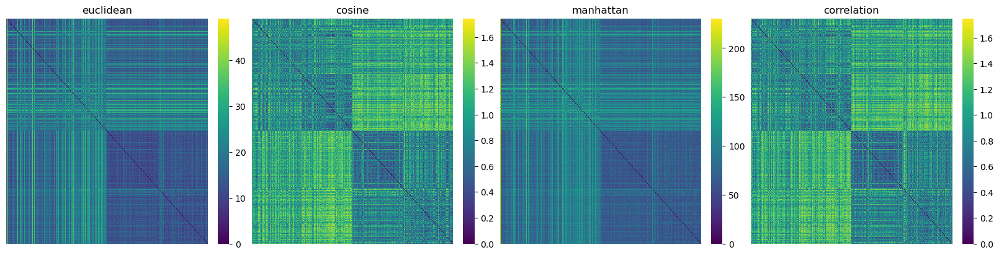

In [16]:
# Keep absolute scale per metric
n = len(metrics)
fig, axes = plt.subplots(1, n, figsize=(4*n, 4), constrained_layout=True)

for ax, metric in zip(axes, metrics):
    D = distance_matrices[metric]
    sns.heatmap(D, ax=ax, cmap="viridis", 
                xticklabels=False, yticklabels=False,
                cbar=True,
               )
    ax.set_title(metric)

plt.show()